In [3]:
import xarray as xr

In [4]:
%cd /home/links/mf671/DATA/isca_data
!pwd

/home/links/mf671/DATA/isca_data
/home/links/mf671/DATA/isca_data


In [5]:
fc_ASYM = xr.open_dataset("exeter_project_mf_baseline_st_KS/tot/FC_1.5x1.5_2-51_wbeta.nc")
fc_SYM  = xr.open_dataset("exeter_project_mf_baseline_KS/tot/FC_1.5x1.5_2-51_wbeta.nc")
lwa_ASYM = xr.open_dataset("exeter_project_mf_baseline_st_KS/tot/filtered_decomposition_data_flipped_2-51.nc")
lwa_SYM = xr.open_dataset("exeter_project_mf_baseline_KS/tot/filtered_decomposition_data_flipped_2-51.nc")

In [6]:
beta = fc_ASYM['beta'].values
alpha = fc_ASYM['alpha'].values
A0 = fc_ASYM['qslwa'].values

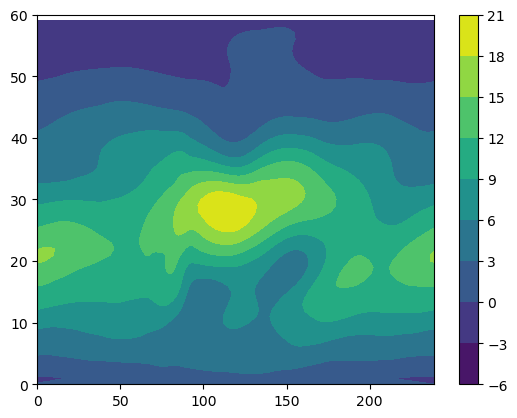

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point

plt.contourf(beta)
plt.colorbar()

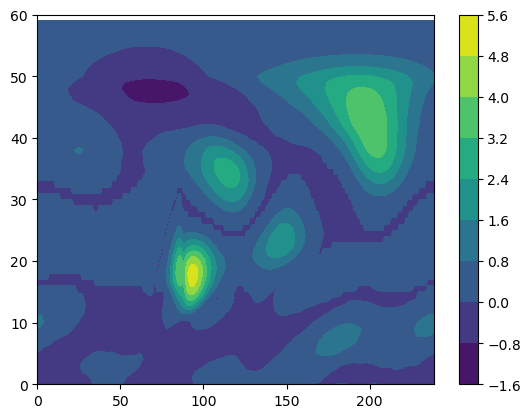

In [11]:
plt.contourf((1-alpha)*A0)
plt.colorbar()

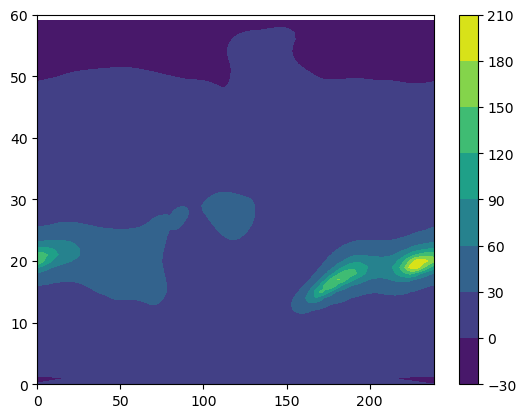

In [8]:
plt.contourf()
plt.colorbar()

In [12]:
def compute_ac(alpha,beta,u0,zgv,A0):
    cx = u0 + zgv + beta - 2*alpha*A0
    ac = cx/(2*alpha)
    return ac

In [15]:
ac_SYM = compute_ac(fc_SYM['alpha'],fc_SYM['beta'],fc_SYM['u_0'],fc_SYM['zgv'],fc_SYM['qslwa'])
ac_ASYM = compute_ac(fc_ASYM['alpha'],fc_ASYM['beta'],fc_ASYM['u_0'],fc_ASYM['zgv'],fc_ASYM['qslwa'])

In [27]:
lwa_mean_SYM = lwa_SYM['dw_lwa'].mean(dim='time') - fc_SYM['qslwa']
lwa_mean_ASYM = lwa_ASYM['dw_lwa'].mean(dim='time') - fc_ASYM['qslwa']

In [28]:
#lwa_mean_SYM = lwa_SYM['dw_lwa'].quantile(0.85, dim='time') - fc_SYM['qslwa']
#lwa_mean_ASYM = lwa_ASYM['dw_lwa'].quantile(0.85, dim='time') - fc_ASYM['qslwa']

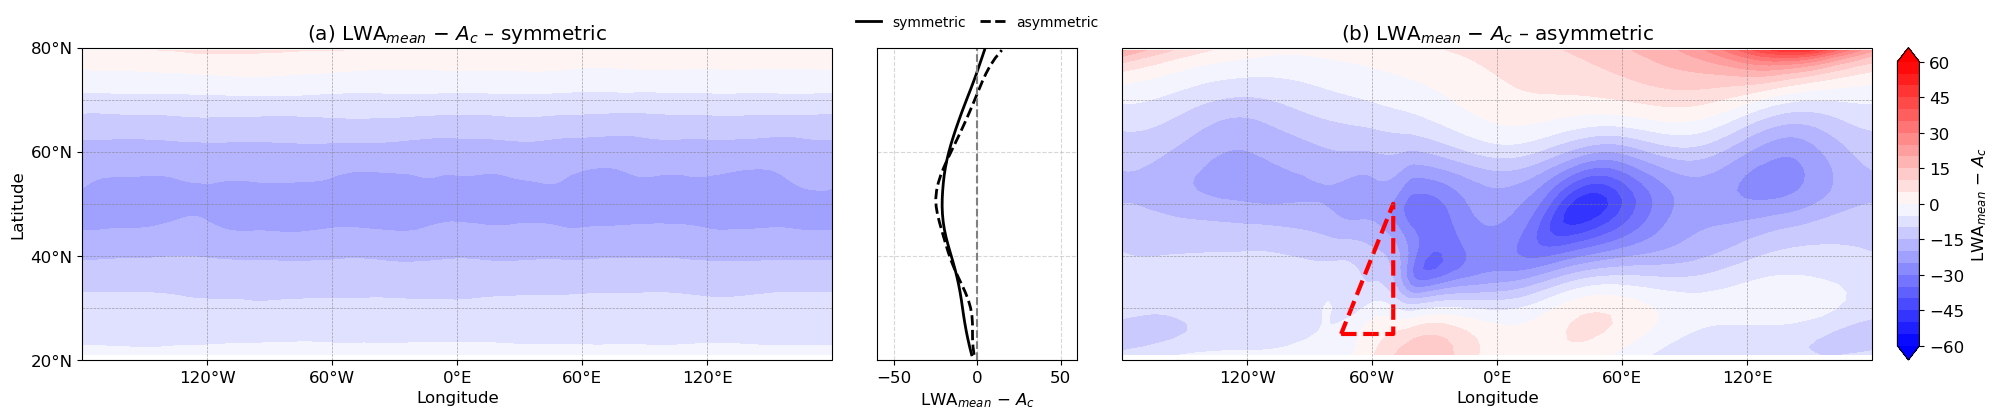

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point

plt.rcParams['font.size'] = 12

# Assumes lwa_mean_SYM, ac_SYM, lwa_mean_ASYM, ac_ASYM are already defined
# (xarray DataArrays with dims lat, lon).

# --------------------------------------------------
# Settings to check
# --------------------------------------------------
LAT_MIN, LAT_MAX = 20, 80

# ADJUSTABLE: contourf levels (maps) and x limits (cross section)
LEVELS = np.linspace(-60, 60, 25)
XLIM   = (-60, 60)
CMAP   = 'bwr'
EXTEND = 'both'

LABEL  = r"LWA$_{mean}$ $-$ $A_c$"     # edit units if needed

def crop_lat(da):
    """Keep only LAT_MIN-LAT_MAX, whatever the latitude ordering."""
    ascending = bool(da.lat[0] < da.lat[-1])
    sl = slice(LAT_MIN, LAT_MAX) if ascending else slice(LAT_MAX, LAT_MIN)
    return da.sel(lat=sl)

def to_180(da):
    """lon -> [-180, 180), sorted."""
    return da.assign_coords(lon=((da.lon + 180) % 360) - 180).sortby('lon')

diff_SYM  = crop_lat(to_180(lwa_mean_SYM  - ac_SYM))
diff_ASYM = crop_lat(to_180(lwa_mean_ASYM - ac_ASYM))
diffs = [diff_SYM, diff_ASYM]
lat = diff_SYM.lat.values

# ==================================================
# Figure layout
# Axes are placed explicitly (sizes in inches) so that the two maps, the cross
# section and the colorbar can never overlap or change size. The map height is
# computed from the map width and the aspect ratio, so the three panels have
# exactly the same height and share the same y axis.
# ==================================================
ASPECT = 2.5                 # degrees of lat drawn 2.5x taller than degrees of lon

MAP_W   = 7.5                # width of each map
XSEC_W  = 2.0                # width of the cross section
GAP     = 0.45               # space between map and cross section
CB_GAP  = 0.25               # space between right map and colorbar
CB_W    = 0.22               # colorbar width
LEFT, RIGHT   = 1.1, 1.1     # outer margins (room for y labels / colorbar label)
BOTTOM, TOP   = 1.0, 0.8     # outer margins (room for x labels / titles+legend)

MAP_H = MAP_W * (LAT_MAX - LAT_MIN) * ASPECT / 360.0

fig_w = LEFT + MAP_W + GAP + XSEC_W + GAP + MAP_W + CB_GAP + CB_W + RIGHT
fig_h = BOTTOM + MAP_H + TOP
fig = plt.figure(figsize=(fig_w, fig_h))

def rect(x, w):
    """Axes rectangle in figure fractions from x position / width in inches."""
    return [x / fig_w, BOTTOM / fig_h, w / fig_w, MAP_H / fig_h]

x_map_L = LEFT
x_xsec  = x_map_L + MAP_W + GAP
x_map_R = x_xsec + XSEC_W + GAP
x_cb    = x_map_R + MAP_W + CB_GAP

titles  = ['symmetric', 'asymmetric']
letters = ['(a)', '(b)']
ls_xsec = ['-', '--']      # SYM solid, ASYM dashed (black)

# red triangle
coords = [(-75.0, 25.0), (-50.0, 25.0), (-50.0, 50.0)]
lons, lats = zip(*coords)
lons_closed = np.append(lons, lons[0])
lats_closed = np.append(lats, lats[0])

proj = ccrs.PlateCarree()

# --------------------------------------------------
# Helpers
# --------------------------------------------------
def style_map(ax_map, i):
    ax_map.set_extent([-180, 180, LAT_MIN, LAT_MAX], crs=proj)
    ax_map.set_aspect(ASPECT)
    ax_map.set_xticks([-120, -60, 0, 60, 120], crs=proj)
    ax_map.set_xticklabels(['120°W', '60°W', '0°E', '60°E', '120°E'])
    ax_map.set_xlabel('Longitude')

    if i == 0:
        ax_map.set_yticks([20, 40, 60, 80])
        ax_map.set_yticklabels(['20°N', '40°N', '60°N', '80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(), visible=False)
        ax_map.plot(lons_closed, lats_closed, '--', lw=3, color='red', transform=proj)

    ax_map.gridlines(draw_labels=False, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')

def style_xsec(ax):
    ax.axvline(0, color='gray', ls='--')
    ax.set_ylim(LAT_MIN, LAT_MAX)
    ax.grid(True, ls='--', alpha=0.5)
    ax.tick_params(axis='y', length=0)
    plt.setp(ax.get_yticklabels(), visible=False)

# --------------------------------------------------
# Plot: SYM map | zonal means | ASYM map | colorbar
# --------------------------------------------------
ax_xsec = fig.add_axes(rect(x_xsec, XSEC_W))
ax_cb   = fig.add_axes(rect(x_cb, CB_W))

for i in range(2):
    x_map = x_map_L if i == 0 else x_map_R
    da = diffs[i]

    ax_map = fig.add_axes(rect(x_map, MAP_W), projection=proj, sharey=ax_xsec)
    ax_map.set_title(f"{letters[i]} {LABEL} – {titles[i]}")

    data, lon = add_cyclic_point(da.values, coord=da.lon.values)
    cf = ax_map.contourf(lon, da.lat.values, data, levels=LEVELS,
                         cmap=CMAP, extend=EXTEND, transform=proj)
    style_map(ax_map, i)

    zm = da.mean('lon', skipna=True).values
    ax_xsec.plot(zm, lat, color='k', ls=ls_xsec[i], lw=2, label=titles[i])

fig.colorbar(cf, cax=ax_cb, label=LABEL)

ax_xsec.set_xlabel(LABEL)
ax_xsec.set_xlim(XLIM)
ax_xsec.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2,
               frameon=False, fontsize=10, handlelength=1.8, columnspacing=1.0)
style_xsec(ax_xsec)

# --------------------------------------------------
#plt.savefig('PLOTS/Figure_diff_SYM_ASYM.png', dpi=200, bbox_inches='tight')
plt.show()